<a href="https://colab.research.google.com/github/Sherezax/TareaProgramadaElectro2_Evaluacion3/blob/main/dipolo_oscilante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dipolo eléctrico oscilante

Yariela Araya Pizarro - B90522

María José Ramírez Rivera - B96394


## 1. Planteamiento y teoría

Tomando como referencia el libro Classical Electrodynamics (3), se establecen las ecuaciones mostradas a continuación. Con $k=\omega/c=2\pi/\lambda$ y la convención temporal $e^{-i\omega t}$, los campos exactos del dipolo (en componentes esféricas, $\mathbf{p}=p_0\hat z$) son

$$E_r = \frac{p_0}{4\pi\varepsilon_0}\,2\cos\theta\left(\frac{1}{r^3}-\frac{ik}{r^2}\right)e^{ikr},$$

$$E_\theta = \frac{p_0}{4\pi\varepsilon_0}\,\sin\theta\left(\frac{1}{r^3}-\frac{ik}{r^2}-\frac{k^2}{r}\right)e^{ikr},$$

$$B_\phi = -\frac{\mu_0}{4\pi}\,p_0\,c\,\sin\theta\,\frac{k^2}{r}\left(1+\frac{i}{kr}\right)e^{ikr}.$$

El campo real es $\mathrm{Re}\left[\,\cdot\,e^{-i\omega t}\right]$.


## 2. Implementación

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, FloatLogSlider, IntSlider, Checkbox, Layout

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

C = 1.0
LAM = 1.0
K = 2 * np.pi / LAM
OMEGA = C * K
T_PER = 2 * np.pi / OMEGA
MU0 = 4 * np.pi
R_MIN = 0.003
DPDO_MAX = K**4 / (8 * np.pi)
P_TOTAL = K**4 / 3


_trapz = getattr(np, "trapezoid", None) or np.trapz

def sl(desc, vmin, vmax, val, step=0.01):
    return FloatSlider(value=val, min=vmin, max=vmax, step=step, description=desc,
                       continuous_update=False, style={"description_width": "80px"},
                       layout=Layout(width="430px"))


def phasors(r, th):
    ph = np.exp(1j * K * r)
    Er = 2 * np.cos(th) * (1 / r**3 - 1j * K / r**2) * ph
    Eth = np.sin(th) * (1 / r**3 - 1j * K / r**2 - K**2 / r) * ph
    Bph = -np.sin(th) * K**2 / r * (1 + 1j / (K * r)) * ph
    return Er, Eth, Bph


def real_fields(r, th, t):
    f = np.exp(-1j * OMEGA * t)
    return tuple(np.real(c * f) for c in phasors(r, th))


def poynting_inst(r, th, t):
    Er, Eth, Bph = real_fields(r, th, t)
    return Eth * Bph / MU0, -Er * Bph / MU0


def poynting_avg_numeric(r, th, n=64):
    Sr = np.zeros(np.broadcast(r, th).shape)
    Sth = np.zeros_like(Sr)
    for t in np.linspace(0, T_PER, n, endpoint=False):
        a, b = poynting_inst(r, th, t)
        Sr = Sr + a
        Sth = Sth + b
    return Sr / n, Sth / n


def poynting_avg_analytic(r, th):
    Er, Eth, Bph = phasors(r, th)
    return 0.5 * np.real(Eth * np.conj(Bph)) / MU0, -0.5 * np.real(Er * np.conj(Bph)) / MU0

### Funciones auxiliares para los mapas en el plano $xz$


In [ ]:
def cart_grid(L, n):
    x = np.linspace(-L, L, n)
    z = np.linspace(-L, L, n)
    X, Z = np.meshgrid(x, z)
    R = np.maximum(np.hypot(X, Z), R_MIN)
    TH = np.arctan2(np.abs(X), Z)
    s = np.where(X >= 0, 1.0, -1.0)
    return x, z, X, Z, R, TH, s


def to_xz(a_r, a_th, s, TH):
    return s * (a_r * np.sin(TH) + a_th * np.cos(TH)), a_r * np.cos(TH) - a_th * np.sin(TH)


def decorar(ax, L, titulo):
    for rr, ls in ((1 / K, ":"), (1.0, "--")):
        if rr < L:
            ax.add_patch(plt.Circle((0, 0), rr, fill=False, ls=ls, ec="k", lw=0.9))
    ax.annotate("", xy=(0, 0.06 * L), xytext=(0, -0.06 * L),
                arrowprops=dict(arrowstyle="<->", lw=2.2, color="k"))
    ax.set_xlim(-L, L)
    ax.set_ylim(-L, L)
    ax.set_aspect("equal")
    ax.set_xlabel(r"$x/\lambda$")
    ax.set_ylabel(r"$z/\lambda$")
    ax.set_title(titulo, fontsize=10)

### Predicción previa para la sección 4.1
 Se usarán estos valores representativos:

| régimen | $r/\lambda$ | $kr$ |
|---|---|---|
| $r\ll\lambda$ | 0.05 | 0.31 |
| $r\sim\lambda/2\pi$ | 0.159 | 1 |
| $r\gg\lambda$ | 5 | 31.4 |

Con los términos del campo a la vista, sin graficar nada, esto es lo que se espera:

**$r\ll\lambda$ ($kr\ll1$).** En $E_r$ y $E_\theta$ dominan los términos $1/r^3$; en $B_\phi$ el primer término es $k/r^2$, entonces:
- $E\gg cB$, con $E/(cB)\approx1/(kr)$, creciendo al acercarse al dipolo.
- $E_r$ del mismo orden que $E_\theta$: campo casi dipolar estático, con componente longitudinal importante.
- $\mathbf{E}$ y $\mathbf{B}$ **en cuadratura de fase**, porque el término $1/r^3$ es real y el de $B$ lleva un factor $i$. Con eso $S_r$ cambiaría de signo y su promedio sería pequeño frente a su valor pico: energía que va y viene.

**$r\sim\lambda/2\pi$ ($kr\sim1$).** Los tres términos $1/r^3$, $k/r^2$ y $k^2/r$ son comparables: región de transición. Se espera que $E/(cB)$ pase de valores mayores que 1 a valores cercanos a 1, de forma monótona.

**$r\gg\lambda$ ($kr\gg1$).** Solo sobrevive el término $k^2/r$: espero $E=cB$, en fase, campos transversales ($E_r\to0$), $S$ siempre hacia afuera y $\langle S_r\rangle$ igual a la mitad del pico. Se supone que la zona de radiación "empieza" hacia $r\sim\lambda$ y que todos los rasgos de onda aparecen a esa distancia.

**Para ver cada régimen**

| figura | $r\ll\lambda$ | $r\sim\lambda/2\pi$ | $r\gg\lambda$ |
|---|---|---|---|
| 3.1(a) (líneas de $\mathbf{E}$, $B_y$) | `L/λ` = 0.1 | `L/λ` = 0.3 | `L/λ` = 5 |
| 3.4(a) y 3.4(b) (Poynting) | `L/λ` = 0.1 | `L/λ` = 0.3 | `L/λ` = 5 |
| 3.3 ($\mathbf{E}$, $\mathbf{B}$, $\mathbf{S}$ en 3D) | `r0/λ` = 0.05 | `r0/λ` = 0.16 | `r0/λ` = 5 |
| 3.1(b) y 3.2 (perfil y términos) | un solo gráfico cubre los tres regímenes: ver las líneas verticales en $\lambda/2\pi$ y $\lambda$ |

## 3. Aspectos mínimos que deben quedar visibles

## 3.1 Dependencia espacial de los campos respecto a $r$ para un tiempo $t$

Dos vistas complementarias: un mapa 2D del plano $xz$ (a) y el perfil a lo largo de una dirección (b).

### 3.1(a) Líneas de $\mathbf{E}$ y campo magnético $B_y$

**Qué muestra:** las líneas del campo eléctrico real (negro) y, en color, la componente $B_y$ (perpendicular al plano, pues $\mathbf{B}=B_\phi\hat\phi$) en el plano $xz$ a un tiempo $t$.

**Qué observar:**
- Con $L\lesssim\lambda/2\pi$ (zona cercana) las líneas parecen las de un dipolo estático.
- Al aumentar $L$ las líneas se desprenden y forman lazos cerrados que se propagan hacia afuera (zona de radiación).
- Cuando $\mathbf{E}$ y $B_y$ se vuelven transversales y están en fase, el campo es el de una onda.

**Sliders:** `t/T` (tiempo en periodos) y `L/λ` (semiancho de la ventana; sirve de zoom entre zona cercana y lejana).

In [ ]:
def grafica_mapa_E(t=0.1, L=2.0):
    x, z, X, Z, R, TH, s = cart_grid(L, 141)
    Er, Eth, Bph = real_fields(R, TH, t)
    By = s * Bph
    Ex, Ez = to_xz(Er, Eth, s, TH)
    vmax = np.percentile(np.abs(By), 96)

    fig, ax = plt.subplots(figsize=(7, 6))
    pcm = ax.pcolormesh(X, Z, By, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                        shading="auto", rasterized=True)
    ax.streamplot(x, z, Ex, Ez, color="k", density=1.5, linewidth=0.6, arrowsize=0.8)
    fig.colorbar(pcm, ax=ax, shrink=0.8, label=r"$B_y$ (u.a.)")
    decorar(ax, L, rf"Líneas de $\mathbf{{E}}$ y $B_y$ (color),  $t/T={t:.2f}$" "\n"
                   r"(punteado: $r=\lambda/2\pi$,  discontinuo: $r=\lambda$)")
    plt.show()


interact(grafica_mapa_E,
         t=sl("t/T", 0, 1, 0.1, 0.02),
         L=sl("L/λ (zoom)", 0.05, 5, 2.0, 0.05));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='t/T', layout=Layout(width='…

### 3.1(b) Perfil radial de los campos a un $t$ fijo

**Qué muestra:** $E_r(r)$, $E_\theta(r)$ y $cB_\phi(r)$ a lo largo de una dirección $\theta$ fija, para un tiempo $t$ dado. Responde directamente a la dependencia espacial de los campos con $r$.

**Qué observar:**
- Cerca del dipolo ($r<\lambda/2\pi$) $E$ es enorme y $B$ pequeño.
- Para $r\gtrsim\lambda$ aparecen oscilaciones de longitud de onda $\lambda$ y amplitud decreciente como $1/r$, con $E_\theta$ y $cB_\phi$ superpuestos (transversalidad y $E=cB$).
- En $\theta=90^\circ$ se tiene $E_r=0$; para otros ángulos aparece $E_r$, que decae rápido (como $1/r^3$ y $1/r^2$) y desaparece en la zona de radiación.

**Sliders:** `t/T`, `θ` (ángulo respecto al eje del dipolo), `r_max/λ` y una casilla para escala `symlog` (permite ver a la vez los valores enormes cerca del dipolo y las oscilaciones lejanas).

In [ ]:
def grafica_perfil(t=0.1, theta_deg=90, r_max=4.0, symlog=True):
    th = np.radians(theta_deg)
    r = np.linspace(0.05, r_max, 3000)
    Er, Eth, Bph = real_fields(r, th, t)

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(r, Er, color="tab:green", label=r"$E_r$")
    ax.plot(r, Eth, color="tab:blue", label=r"$E_\theta$")
    ax.plot(r, C * Bph, color="tab:red", ls="--", label=r"$c\,B_\phi$")
    if symlog:
        ax.set_yscale("symlog", linthresh=20)
    ax.axvline(1 / K, color="k", ls=":", lw=0.9, label=r"$r=\lambda/2\pi$")
    ax.axvline(1.0, color="k", ls="--", lw=0.9, label=r"$r=\lambda$")
    ax.set_xlabel(r"$r/\lambda$")
    ax.set_ylabel("campo (u.a.)")
    ax.set_title(rf"Perfil radial, $\theta={theta_deg:.0f}^\circ$,  $t/T={t:.2f}$")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
    plt.show()


interact(grafica_perfil,
         t=sl("t/T", 0, 1, 0.1, 0.02),
         theta_deg=sl("θ [°]", 5, 175, 90, 5),
         r_max=sl("r_max/λ", 1, 10, 4, 0.5),
         symlog=Checkbox(value=True, description="escala symlog"));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='t/T', layout=Layout(width='…

## 3.2 Región cercana frente a región de radiación: términos $1/r^3$, $1/r^2$ y $1/r$

**Qué muestra:** en escala log-log, la magnitud de cada término de $E_\theta$ y de $B_\phi$ (más $E_r$ si $\theta\neq90^\circ$) frente a $r/\lambda$, junto con el valor total.

**Cómo leer la gráfica:** una potencia $r^{-n}$ es una recta de pendiente $-n$.
- A la izquierda de $r=\lambda/2\pi$ (línea punteada) la recta de pendiente $-3$ (electrostático) es la mayor: **cerca del dipolo dominan los términos $1/r^3$**.
- Cerca de $r\sim\lambda/2\pi$ los tres términos son comparables.
- A la derecha, para $r\gg\lambda$, solo la recta de pendiente $-1$ (radiación) queda por encima: **solo sobrevive el término $1/r$**. Además $E$ y $cB$ coinciden: es el término transversal.

**Slider:** `θ`. Los términos de $E_\theta$ y $B_\phi$ se multiplican por $\sin\theta$ (solo cambian de escala), mientras que $E_r\propto\cos\theta$ solo aparece fuera del plano ecuatorial. El slider `r_min` ajusta el extremo izquierdo del eje.

In [ ]:
def grafica_terminos(theta_deg=90, log_rmin=-1.5):
    th = np.radians(theta_deg)
    r = np.logspace(log_rmin, 1.0, 500)
    Er, Eth, Bph = phasors(r, th)
    s_, c_ = np.sin(th), np.cos(th)

    fig, ax = plt.subplots(figsize=(9, 5.2))
    ax.loglog(r, s_ / r**3, color="tab:green", label=r"$E_\theta$: $\sin\theta/r^3$ (electrostático)")
    ax.loglog(r, s_ * K / r**2, color="tab:orange", label=r"$E_\theta$: $k\sin\theta/r^2$ (inducción)")
    ax.loglog(r, s_ * K**2 / r, color="tab:purple", label=r"$E_\theta$, $cB_\phi$: $k^2\sin\theta/r$ (radiación)")
    ax.loglog(r, np.abs(Eth), "k-", lw=2.2, label=r"$|E_\theta|$ total")
    ax.loglog(r, np.abs(C * Bph), "r--", lw=1.6, label=r"$c|B_\phi|$ total")
    if abs(c_) > 1e-6:
        ax.loglog(r, np.abs(Er), color="gray", lw=1.4, ls="-.", label=r"$|E_r|$ total")
    ax.axvline(1 / K, color="k", ls=":", lw=0.9)
    ax.axvline(1.0, color="k", ls="--", lw=0.9)
    ax.text(1 / K * 1.05, 2e-1, r"$\lambda/2\pi$", fontsize=9)
    ax.text(1.05, 2e-1, r"$\lambda$", fontsize=9)
    ax.set_ylim(1e-1, 1e6)
    ax.set_xlabel(r"$r/\lambda$")
    ax.set_ylabel("amplitud (u.a.)")
    ax.set_title(rf"Términos de los campos, $\theta={theta_deg:.0f}^\circ$")
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.3, which="both")
    plt.show()


interact(grafica_terminos,
         theta_deg=sl("θ [°]", 5, 175, 90, 5),
         log_rmin=sl("log10 r_min", -2.5, -0.5, -1.5, 0.1));

interactive(children=(FloatSlider(value=90.0, continuous_update=False, description='θ [°]', layout=Layout(widt…

## 3.3 Orientación relativa de $\mathbf{E}$, $\mathbf{B}$ y la dirección de propagación

**Qué muestra:** en un punto a distancia $r_0$ (en la zona de radiación si $r_0\gg\lambda$) y ángulo $\theta$, los vectores $\mathbf{E}$ (azul), $\mathbf{B}$ (rojo) y $\mathbf{S}=\frac{1}{\mu_0}\mathbf{E}\times\mathbf{B}$ (verde) en tres dimensiones, junto con el dipolo (barra negra en $z$).

**Qué observar:**
- $\mathbf{E}$ apunta según $\hat\theta$ (está en el plano que contiene al eje), $\mathbf{B}$ según $\hat\phi$ (perpendicular a ese plano) y $\mathbf{S}$ según $\hat r$: son **mutuamente perpendiculares** y forman una terna derecha, $\mathbf{E}\times\mathbf{B}\parallel\hat r$.
- Al mover `t/T`, $\mathbf{E}$ y $\mathbf{B}$ invierten su sentido a la vez; $\mathbf{S}$ sigue apuntando hacia afuera (cambia solo su magnitud).
- Con $r_0$ pequeño (por ejemplo $0.1\lambda$) $\mathbf{E}$ tiene una componente radial apreciable y deja de ser transversal.

**Sliders:** `t/T`, `θ` y `r0/λ`. Las flechas se normalizan para el dibujo, y se muestran con su signo real (si $\mathbf{E}$ se anula en ese instante, la flecha desaparece, porque el campo es genuinamente cero).

In [ ]:
def grafica_3d(t=0.1, theta_deg=60, r0=5.0):
    th = np.radians(theta_deg)
    st, ct = np.sin(th), np.cos(th)
    rh = np.array([st, 0, ct])
    thh = np.array([ct, 0, -st])
    phh = np.array([0, 1.0, 0])
    P = r0 * rh

    Er, Eth, Bph = real_fields(r0, th, t)
    E = Er * rh + Eth * thh
    B = Bph * phh
    S = np.cross(E, B) / MU0

    Ea = np.abs(phasors(r0, th)[1]) + 1e-30
    Ba = np.abs(phasors(r0, th)[2]) + 1e-30
    la = 0.35 * r0
    nS = np.linalg.norm(S) + 1e-300

    fig = plt.figure(figsize=(7.5, 6.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot([0, 0], [0, 0], [-0.4 * r0, 0.4 * r0], "k-", lw=5)
    ax.text(0.05 * r0, 0, 0.45 * r0, r"$\mathbf{p}$", fontsize=13)
    ax.plot([0, P[0]], [0, P[1]], [0, P[2]], color="gray", lw=0.8, ls="--")
    ax.quiver(*P, *(la * E / Ea), color="tab:blue", linewidth=2.5, arrow_length_ratio=0.2)
    ax.quiver(*P, *(la * B / Ba), color="tab:red", linewidth=2.5, arrow_length_ratio=0.2)
    ax.quiver(*P, *(la * S / nS), color="tab:green", linewidth=2.5, arrow_length_ratio=0.2)
    lim = 1.15 * r0
    ax.set_xlim(-0.2 * r0, lim)
    ax.set_ylim(-0.5 * r0, 0.5 * r0)
    ax.set_zlim(-0.3 * r0, lim)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_box_aspect((1.3, 1, 1.3))
    ax.set_title(rf"$r={r0:.2f}\lambda$, $\theta={theta_deg:.0f}^\circ$, $t/T={t:.2f}$" "\n"
                 r"azul: $\mathbf{E}$   rojo: $\mathbf{B}$   verde: $\mathbf{S}$", fontsize=10)
    plt.show()


interact(grafica_3d,
         t=sl("t/T", 0, 1, 0.1, 0.02),
         theta_deg=sl("θ [°]", 5, 175, 60, 5),
         r0=sl("r0/λ", 0.05, 10, 5.0, 0.05));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='t/T', layout=Layout(width='…

## 3.4 Flujo de energía electromagnética: vector de Poynting


### 3.4(a) Vector de Poynting instantáneo $\mathbf{S}(t)$

**Qué muestra:** la dirección de $\mathbf{S}=\frac{1}{\mu_0}\mathbf{E}\times\mathbf{B}$ en el plano $xz$ en el instante $t$. Cada flecha tiene longitud fija (solo indica dirección) y el color da $\log_{10}|\mathbf{S}|$.

**Qué observar:**
- En la zona cercana las flechas **cambian de sentido** con el tiempo, con componentes radial y polar: es energía reactiva que va y viene entre el dipolo y el campo.
- En la zona de radiación $\mathbf{S}$ es casi radial hacia afuera (siempre con $S_r\ge0$ salvo correcciones pequeñas), y su magnitud oscila entre 0 y un máximo, con frecuencia $2\omega$.

**Sliders:** `t/T`, `L/λ` y el número de flechas por lado.

In [ ]:
def grafica_S_inst(t=0.1, L=2.0, n_flechas=18):
    x, z, X, Z, R, TH, s = cart_grid(L, n_flechas)
    Sr, Sth = poynting_inst(R, TH, t)
    Sx, Sz = to_xz(Sr, Sth, s, TH)
    mag = np.hypot(Sx, Sz) + 1e-300

    fig, ax = plt.subplots(figsize=(7, 6))
    q = ax.quiver(X, Z, Sx / mag, Sz / mag, np.log10(mag), cmap="plasma",
                  pivot="mid", angles="xy", width=0.005)
    fig.colorbar(q, ax=ax, shrink=0.8, label=r"$\log_{10}|\mathbf{S}|$")
    decorar(ax, L, rf"Poynting instantáneo $\mathbf{{S}}(t)$,  $t/T={t:.2f}$")
    plt.show()


interact(grafica_S_inst,
         t=sl("t/T", 0, 1, 0.1, 0.02),
         L=sl("L/λ (zoom)", 0.05, 5, 2.0, 0.05),
         n_flechas=IntSlider(value=18, min=8, max=40, step=2, description="flechas",
                             continuous_update=False, layout=Layout(width="430px")));

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='t/T', layout=Layout(width='…

### 3.4(b) Poynting promedio temporal $\langle\mathbf{S}\rangle$

**Qué muestra:** el promedio $\langle\mathbf{S}\rangle=\frac1T\int_0^T\mathbf{S}(t)\,dt$ calculado **numéricamente** como suma de Riemann con `n_t` instantes equiespaciados en un periodo, y comparado con la fórmula analítica $\frac{1}{2\mu_0}\mathrm{Re}(\mathbf{E}\times\mathbf{B}^*)$. El título muestra el error relativo entre ambos.

**Qué observar:**
- $\langle\mathbf{S}\rangle$ es **puramente radial** en *todo* el espacio (la parte reactiva se promedia a cero), y su magnitud es $\propto\sin^2\theta/r^2$.
- $S(t)$ solo contiene las frecuencias $0$ y $2\omega$, así que la suma de Riemann ya es exacta con `n_t` $\ge3$; con `n_t` $=1$ o $2$ el error es grande.

**Sliders:** `L/λ`, `n_t` (instantes por periodo) y número de flechas.

In [ ]:
def grafica_S_promedio(L=2.0, n_t=64, n_flechas=18):
    x, z, X, Z, R, TH, s = cart_grid(L, n_flechas)
    Sr, Sth = poynting_avg_numeric(R, TH, n_t)
    Sr_a, Sth_a = poynting_avg_analytic(R, TH)
    err = np.max(np.hypot(Sr - Sr_a, Sth - Sth_a)) / np.max(np.abs(Sr_a))
    Sx, Sz = to_xz(Sr, Sth, s, TH)
    mag = np.hypot(Sx, Sz) + 1e-300

    fig, ax = plt.subplots(figsize=(7, 6))
    q = ax.quiver(X, Z, Sx / mag, Sz / mag, np.log10(mag), cmap="plasma",
                  pivot="mid", angles="xy", width=0.005)
    fig.colorbar(q, ax=ax, shrink=0.8, label=r"$\log_{10}|\langle\mathbf{S}\rangle|$")
    decorar(ax, L, rf"Poynting promedio $\langle\mathbf{{S}}\rangle$ ($n_t={n_t}$ instantes)" "\n"
                   rf"error relativo vs. analítico: {err:.1e}")
    plt.show()


interact(grafica_S_promedio,
         L=sl("L/λ (zoom)", 0.05, 5, 2.0, 0.05),
         n_t=IntSlider(value=64, min=1, max=64, step=1, description="n_t",
                       continuous_update=False, layout=Layout(width="430px")),
         n_flechas=IntSlider(value=18, min=8, max=40, step=2, description="flechas",
                             continuous_update=False, layout=Layout(width="430px")));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='L/λ (zoom)', layout=Layout(…

## 3.5 Patrón angular de radiación $dP/d\Omega$

**Qué muestra:** la potencia radiada por unidad de ángulo sólido,

$$\frac{dP}{d\Omega}=r^2\,\langle S_r\rangle=\frac{\mu_0\,p_0^2\,\omega^4}{32\pi^2 c}\,\sin^2\theta,$$

en un diagrama polar normalizado (eje del dipolo vertical). La línea negra es $\sin^2\theta$; los marcadores son $r^2\langle S_r\rangle$ **calculado numéricamente** a la distancia $r$ que elijas.

**Qué observar:**
- Forma de "ocho" (toroide al girar alrededor de $z$): **máximo en el plano ecuatorial** ($\theta=90^\circ$) y **cero a lo largo del eje** del dipolo ($\theta=0,\pi$). El dipolo no radia en la dirección en que oscila.
- Los marcadores caen sobre la curva para *cualquier* $r$ (incluso $r\ll\lambda$): $r^2\langle S_r\rangle$ no depende de $r$, y por eso la potencia total que cruza una esfera es la misma a cualquier radio.

**Slider:** `r/λ` (logarítmico, de 0.03 a 30). El título muestra la potencia total numérica comparada con $\mu_0p_0^2\omega^4/(12\pi c)$.

In [ ]:
def grafica_polar(r0=1.0):
    th_fino = np.linspace(0, 2 * np.pi, 361)
    th_pts = np.radians(np.arange(0, 360, 10))

    Sr, _ = poynting_avg_numeric(np.full_like(th_pts, r0), th_pts)
    dpdo = r0**2 * Sr / DPDO_MAX


    thg = np.linspace(0, np.pi, 2001)
    Sg, _ = poynting_avg_numeric(np.full_like(thg, r0), thg)
    P_num = _trapz(r0**2 * Sg * 2 * np.pi * np.sin(thg), thg)

    fig = plt.figure(figsize=(6.5, 6.5))
    ax = fig.add_subplot(111, projection="polar")
    ax.plot(th_fino, np.sin(th_fino) ** 2, "k-", lw=2, label=r"teoría: $\sin^2\theta$")
    ax.plot(th_pts, dpdo, "o", color="tab:purple", mfc="none", ms=6,
            label=rf"numérico: $r^2\langle S_r\rangle$, $r={r0:.2f}\lambda$")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rticks([0.5, 1.0])
    ax.set_title(r"$dP/d\Omega\,/\,(dP/d\Omega)_{\max}$   (eje del dipolo vertical)" "\n"
                 rf"$P_{{num}}={P_num:.2f}$   $P_{{teoría}}={P_TOTAL:.2f}$", fontsize=10, pad=18)
    ax.legend(loc="lower left", bbox_to_anchor=(-0.15, -0.12), fontsize=8)
    plt.show()


interact(grafica_polar,
         r0=FloatLogSlider(value=1.0, base=10, min=-1.5, max=1.5, step=0.05,
                           description="r/λ", continuous_update=False,
                           style={"description_width": "80px"}, layout=Layout(width="430px")));

interactive(children=(FloatLogSlider(value=1.0, continuous_update=False, description='r/λ', layout=Layout(widt…

# 4. Interpretación física


## 4.1 Región cercana y región de radiación

**Distancias representativas:** $r=0.05\lambda$ ($r\ll\lambda$), $r=\lambda/2\pi\approx0.159\lambda$ ($r\sim\lambda/2\pi$) y $r=5\lambda$ ($r\gg\lambda$).

**Predicción.** Se escribió en la sección 2, *antes de generar cualquier figura* (subsección "Predicción previa para la sección 4.1"). Aquí se contrasta con los resultados.

**Visualizaciones comparativas.** Las figuras 3.1 a 3.4 ya permiten comparar los tres regímenes (la tabla de configuración está en la predicción). Para tener evidencia cuantitativa se añaden tres celdas: **4.1-A** (series temporales de $E_\theta$ y $cB_\phi$ en un radio de cada régimen), **4.1-B** (cocientes en función de $r$ con los tres regímenes marcados) y **4.1-C** (tabla de valores citados en el análisis).

In [ ]:
R_NEAR, R_TRANS, R_FAR = 0.05, 1 / (2 * np.pi), 5.0
REGIMENES = [("r << λ", R_NEAR), ("r ~ λ/2π", R_TRANS), ("r >> λ", R_FAR)]
COLORES = ["tab:green", "tab:orange", "tab:purple"]


def slog(desc, emin, emax, val):
    return FloatLogSlider(value=val, base=10, min=emin, max=emax, step=0.02, description=desc,
                          continuous_update=False, style={"description_width": "80px"},
                          layout=Layout(width="430px"))


def S_series(r, th, n=256):
    t = np.linspace(0, T_PER, n, endpoint=False)[:, None]
    return poynting_inst(np.atleast_1d(r), th, t)

**Figura 4.1-A: series temporales en cada régimen.** En un punto a un ángulo $\theta$ y a un radio de cada régimen se dibujan $E_\theta(t)$ y $cB_\phi(t)$ durante un periodo, normalizados por la amplitud de $E_\theta$. Así se ven a la vez el cociente de amplitudes y el desfase entre $\mathbf{E}$ y $\mathbf{B}$. Cada título da $|E_\theta|/(c|B_\phi|)$ y el desfase.

In [ ]:
def figura_series(theta_deg=90, r_cerca=R_NEAR, r_trans=R_TRANS, r_lejos=R_FAR):
    th = np.radians(theta_deg)
    t = np.linspace(0, 1, 400)
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
    for ax, r, (nom, _) in zip(axs, (r_cerca, r_trans, r_lejos), REGIMENES):
        Er, Eth, Bph = real_fields(r, th, t)
        amp = np.max(np.abs(Eth))
        ax.plot(t, Eth / amp, color="tab:blue", label=r"$E_\theta$")
        ax.plot(t, C * Bph / amp, color="tab:red", ls="--", label=r"$cB_\phi$")
        _, Ec, Bc = phasors(r, th)
        ratio = abs(Ec) / abs(C * Bc)
        dphi = abs(np.degrees(np.angle(Ec / Bc)))
        ax.set_title(rf"{nom}:  $r={r:.3f}\lambda$" "\n"
                     rf"$|E|/c|B|={ratio:.2f}$,  desfase $={dphi:.1f}^\circ$", fontsize=10)
        ax.set_xlabel(r"$t/T$"); ax.grid(alpha=0.3)
    axs[0].set_ylabel(r"campo / amplitud de $E_\theta$")
    axs[0].legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()


interact(figura_series,
         theta_deg=sl("θ [°]", 5, 175, 90, 5),
         r_cerca=slog("r cerca /λ", -2, -0.5, R_NEAR),
         r_trans=slog("r transición /λ", -1.2, 0, R_TRANS),
         r_lejos=slog("r lejos /λ", 0, 1.5, R_FAR));

interactive(children=(FloatSlider(value=90.0, continuous_update=False, description='θ [°]', layout=Layout(widt…

**Figura 4.1-B: cocientes en función de $r$.** Cuatro magnitudes en un barrido continuo de $r$ (escala logarítmica), con los tres regímenes marcados por líneas verticales: (a) $|E_\theta|/(c|B_\phi|)$ con su expresión analítica $\sqrt{(1-x^2+x^4)/(x^2+x^4)}$, $x=kr$; (b) desfase entre $E_\theta$ y $B_\phi$; (c) componente longitudinal $|E_r|/|E_\theta|$ al ángulo $\theta$ del slider; (d) fracción neta del flujo $\langle S_r\rangle/\max_t|S_r|$ y componente polar instantánea $\max_t|S_\theta|/\max_t|S_r|$.

In [ ]:
def figura_cocientes(theta_deg=45):
    th = np.radians(theta_deg)
    r = np.logspace(-1.5, 1.0, 400)
    x = K * r
    Er, Eth, Bph = phasors(r, th)
    ratio = np.abs(Eth) / np.abs(C * Bph)
    ratio_teo = np.sqrt((1 - x**2 + x**4) / (x**2 + x**4))
    dphi = np.abs(np.degrees(np.angle(Eth / Bph)))
    ratio_Er = np.abs(Er) / np.abs(Eth)
    Sr, Sth = S_series(r, th)
    neto = Sr.mean(0) / np.abs(Sr).max(0)
    polar = np.abs(Sth).max(0) / np.abs(Sr).max(0)

    fig, axs = plt.subplots(2, 2, figsize=(13, 8.2))
    (a, b), (c, d) = axs
    a.semilogx(r, ratio, "k-", lw=2, label="numérico")
    a.semilogx(r, ratio_teo, "y:", lw=2, label=r"$\sqrt{(1-x^2+x^4)/(x^2+x^4)}$")
    a.axhline(1, color="gray", lw=0.8)
    a.set_ylim(0, 5); a.set_ylabel(r"$|E_\theta|\,/\,c|B_\phi|$")
    b.semilogx(r, dphi, "k-", lw=2); b.set_ylabel("desfase $E_\\theta$–$B_\\phi$ [°]")
    c.loglog(r, ratio_Er, "k-", lw=2); c.set_ylabel(rf"$|E_r|/|E_\theta|$  ($\theta={theta_deg:.0f}^\circ$)")
    d.semilogx(r, neto, "k-", lw=2, label=r"$\langle S_r\rangle/\max|S_r|$")
    d.semilogx(r, polar, "m--", lw=2, label=r"$\max|S_\theta|/\max|S_r|$")
    d.set_ylim(0, 1.6)
    for ax in (a, b, c, d):
        for (nom, rr), col in zip(REGIMENES, COLORES):
            ax.axvline(rr, color=col, lw=1.6, alpha=0.9)
        ax.set_xlabel(r"$r/\lambda$"); ax.grid(alpha=0.3, which="both")
    a.legend(fontsize=8, loc="upper right"); d.legend(fontsize=8, loc="upper right")
    fig.suptitle("Verde: r = 0.05 λ   Naranja: r = λ/2π   Morado: r = 5 λ", fontsize=10)
    plt.tight_layout()
    plt.show()


interact(figura_cocientes, theta_deg=sl("θ [°]", 5, 175, 45, 5));

interactive(children=(FloatSlider(value=45.0, continuous_update=False, description='θ [°]', layout=Layout(widt…

**Tabla 4.1-C: valores de las características comparadas.** Fuente de los números del análisis. El cociente $E/cB$, el desfase y $\langle S_r\rangle/\max|S_r|$ no dependen de $\theta$; $|E_r/E_\theta|$ y $\max|S_\theta|/\max|S_r|$ sí (usar $\theta=45^\circ$ para reproducir lo citado).

In [ ]:
def tabla_regimenes(theta_deg=45):
    th = np.radians(theta_deg)
    enc = (f"{'régimen':>10} {'r/λ':>7} {'kr':>6} | {'1/r³':>6} {'k/r²':>6} {'k²/r':>6} | "
           f"{'E/cB':>6} {'desfase':>8} {'|Er/Eθ|':>8} {'<Sr>/Sr,max':>12} {'Sθ,max/Sr,max':>14}")
    print(f"θ = {theta_deg:.0f}°   (pesos de los términos en %, normalizados a su suma)")
    print(enc); print("-" * len(enc))
    for nombre, r in REGIMENES:
        t1, t2, t3 = 1 / r**3, K / r**2, K**2 / r
        tot = t1 + t2 + t3
        Er, Eth, Bph = phasors(r, th)
        Sr, Sth = S_series(r, th)
        print(f"{nombre:>10} {r:7.3f} {K*r:6.2f} | {100*t1/tot:5.1f}% {100*t2/tot:5.1f}% {100*t3/tot:5.1f}% | "
              f"{abs(Eth)/abs(C*Bph):6.3f} {abs(np.degrees(np.angle(Eth/Bph))):7.1f}° "
              f"{abs(Er)/abs(Eth):8.3f} {Sr.mean()/np.abs(Sr).max():12.3f} {np.abs(Sth).max()/np.abs(Sr).max():14.3f}")
    rr = np.linspace(0.02, 3, 20000)
    _, E, B = phasors(rr, np.pi / 2)
    q = np.abs(E) / np.abs(B)
    i = q.argmin()
    print(f"\nE/cB cruza 1 en kr = {K*rr[np.where(np.diff(np.sign(q - 1)))[0][0]]:.3f} (teoría: 1/√2 = 0.707);  "
          f"mínimo {q[i]:.3f} en kr = {K*rr[i]:.2f} (r = {rr[i]:.3f} λ)")


interact(tabla_regimenes, theta_deg=sl("θ [°]", 5, 175, 45, 5));

interactive(children=(FloatSlider(value=45.0, continuous_update=False, description='θ [°]', layout=Layout(widt…

### Análisis: tres características que cambian al pasar de una región a otra

#### Característica 1: el cociente $E/(cB)$

1. **Dónde se observa.** En la **figura 3.2**: cerca del dipolo la curva de $|E_\theta|$ está muy por encima de la de $c|B_\phi|$, y para $r\gtrsim\lambda$ se superponen. En **4.1-A**, la curva roja ($cB_\phi$) es mucho más pequeña que la azul en el primer panel y se monta sobre ella en el tercero; en **4.1-B(a)** se ve el cociente completo. Valores: $E/cB=2.90$ en $r=0.05\lambda$, $0.707$ en $r=\lambda/2\pi$, $0.975$ en $r=\lambda$ y $0.999$ en $r=5\lambda$.
2. **Términos responsables.** En $E_\theta$ domina $1/r^3$ cerca (70.8 % del peso a $0.05\lambda$) y $k^2/r$ lejos (96.8 % a $5\lambda$). En $B_\phi$ el primer término es $k/r^2$ cerca y $k^2/r$ lejos. Con $x=kr$:
   $$\frac{|E_\theta|^2}{c^2|B_\phi|^2}=\frac{1-x^2+x^4}{x^2+x^4},$$
   que vale $\approx1/x^2$ para $x\to0$ y $\approx1-2/x^2$ para $x\to\infty$.
3. **Explicación física.** Cerca del dipolo $\mathbf{E}$ es el campo casi estático de las cargas $\pm q$ que oscilan, $\sim p/r^3$, mientras que $\mathbf{B}$ lo genera la corriente $\dot p$ (tipo Biot–Savart), $\sim\dot p/r^2$; su cociente es $\sim1/kr$. Lejos el campo es una onda desprendida de la fuente, y en una onda $E=cB$.
4. **¿Coincidió con la predicción?** En parte. Se confirmó que $E>cB$ cerca y que $E\to cB$ lejos. No coincidió en dos detalles: (i) a $0.05\lambda$ el cociente es solo 2.9, no "$\gg1$", porque $kr=0.31$ no es tan pequeño y todavía hay 22 % de peso en el término $k/r^2$; (ii) el cociente **no decrece monótonamente**: cruza 1 en $kr=1/\sqrt2$ ($r\approx0.113\lambda$), tiene un mínimo de 0.68 en $kr\approx1.17$ ($r\approx0.186\lambda$) y vuelve a 1 **desde abajo**. El razonamiento inicial comparaba solo las potencias dominantes de $r$ y sumaba los términos como si fueran magnitudes. Pero en $E_\theta$ los términos $1/r^3$ y $-k^2/r$ tienen signo opuesto y en la transición se cancelan parcialmente (factor $1-x^2$), de modo que $|E_\theta|$ baja más rápido que $c|B_\phi|$.

#### Característica 2: el desfase entre $\mathbf{E}$ y $\mathbf{B}$ y el flujo neto de energía

1. **Dónde se observa.** En **4.1-A**: curvas en cuadratura en el primer panel y superpuestas en el tercero; en **4.1-B(b)** y **4.1-B(d)**. Y en las **figuras 3.4(a) y 3.4(b)**: con `L/λ` = 0.1 el Poynting instantáneo cambia de sentido con el tiempo (mueve el slider `t/T`) mientras que $\langle\mathbf{S}\rangle$ apunta siempre hacia afuera; con `L/λ` = 5 el instantáneo ya es casi radial. Valores: desfase de $88.2^\circ$ a $0.05\lambda$, $45.0^\circ$ a $\lambda/2\pi$, $1.8^\circ$ a $0.5\lambda$ y $\approx0^\circ$ a $5\lambda$. Correlativamente $\langle S_r\rangle/\max|S_r|$ vale $0.030$, $0.414$ y $0.500$ en los tres regímenes, y en $0.05\lambda$ el flujo radial instantáneo llega a valores negativos de casi el mismo tamaño que los positivos ($S_{r,\min}/S_{r,\max}=-0.94$ a $60^\circ$).
2. **Términos responsables.** Cerca, el término dominante de $E_\theta$ ($1/r^3$) es real, mientras que $B_\phi\propto\frac{k^2}{r}\cdot\frac{i}{kr}$ lleva un factor $i$: cuadratura. Lejos, ambos están dominados por $-k^2\sin\theta/r$, real y de la misma fase.
3. **Explicación física.** En fase, $S_r=E_\theta B_\phi/\mu_0\propto\cos^2(kr-\omega t)\ge0$: la energía siempre sale y el promedio es la mitad del pico. En cuadratura, $S_r\propto\sin(2\omega t)$ con promedio casi nulo: la energía se almacena en el campo cercano y vuelve a la fuente cada medio ciclo (campo reactivo).
4. **¿Coincidió con la predicción?** La cuadratura y el promedio casi nulo cerca del dipolo, sí. No coincidió la suposición de que todos los rasgos de onda aparecen a $r\sim\lambda$: el desfase ya es de $1.8^\circ$ a $0.5\lambda$ y $\langle S_r\rangle/\max|S_r|$ ya es $0.4999$, es decir, desde $r\approx0.5\lambda$ el flujo radial es el de una onda. Debí separar los rasgos: no todos "entran" a la zona de radiación a la misma distancia (ver característica 3).

#### Característica 3: la componente longitudinal $E_r$

1. **Dónde se observa.** En **4.1-B(c)** y en la tabla 4.1-C ($\theta=45^\circ$): $|E_r|/|E_\theta|=2.20$ a $0.05\lambda$, $2.83$ a $\lambda/2\pi$, $0.70$ a $0.5\lambda$, $0.33$ a $\lambda$, $0.16$ a $2\lambda$ y $0.064$ a $5\lambda$. También en la **figura 3.1(b)** con $\theta=45^\circ$ (aparece la curva de $E_r$ cerca del dipolo y se extingue con $r$), en la **figura 3.2** (curva gris $|E_r|$) y en la **figura 3.1(a)**: con `L/λ` = 0.1 las líneas de $\mathbf{E}$ salen radialmente del dipolo; con `L/λ` = 5 son lazos cerrados transversales a la propagación.
2. **Términos responsables.** $E_r=2\cos\theta\,(1/r^3-ik/r^2)e^{ikr}$ **no tiene término $1/r$**; decae como $1/r^2$ a lo sumo. Frente a $E_\theta$, que conserva $-k^2\sin\theta/r$, el cociente cae como $2\cot\theta/(kr)$.
3. **Explicación física.** Una onda esférica lejana es transversal. El campo longitudinal es un residuo del carácter casi estático y de inducción del campo cercano, y se desvanece con la distancia.
4. **¿Coincidió con la predicción?** Sí en que $E_r\to0$ lejos, pero la caída es lenta ($\propto1/kr$): a $r=\lambda$ todavía es 33 % de $E_\theta$ a $45^\circ$, y hace falta llegar a $r\gtrsim5\lambda$ para bajar del 7 %. La transversalidad completa llega mucho más lejos que $\lambda$, aunque el flujo de energía ya sea ondulatorio desde $\sim0.5\lambda$. La frontera entre región cercana y de radiación depende de **qué propiedad** se mire.

**Resumen.** Las tres características confirman la predicción cualitativa, pero la zona de transición resultó más rica de lo esperado: no es un único radio, sino que cada propiedad (cociente de amplitudes, fase y flujo neto, transversalidad) adquiere su forma ondulatoria a un valor distinto de $kr$.

## 4.2 Patrón angular de radiación

La potencia por unidad de ángulo sólido es $\dfrac{dP}{d\Omega}=r^2\langle S_r\rangle$. La figura muestra el valor numérico (marcadores, con $\langle S_r\rangle$ calculado como promedio sobre un periodo) en un radio ajustable, junto con $\sin^2\theta$ (línea negra). Debajo se imprime una tabla con **cinco direcciones** ($0^\circ$, $30^\circ$, $45^\circ$, $60^\circ$, $90^\circ$) y se comprueba que el resultado no depende del radio elegido.

In [ ]:
ANGULOS = (0, 30, 45, 60, 90)


def dpdo_rel(r0, th):
    Sr, _ = poynting_avg_numeric(np.atleast_1d(r0), np.atleast_1d(th))
    return np.squeeze(r0**2 * Sr / DPDO_MAX)


def figura_polar(r0=1.0):
    th_fino = np.linspace(0, 2 * np.pi, 361)
    th_pts = np.radians(np.arange(0, 360, 10))
    dpdo = dpdo_rel(np.full_like(th_pts, r0), th_pts)

    fig = plt.figure(figsize=(6.2, 6.2))
    ax = fig.add_subplot(111, projection="polar")
    ax.plot(th_fino, np.sin(th_fino) ** 2, "k-", lw=2, label=r"$\sin^2\theta$")
    ax.plot(th_pts, dpdo, "o", color="tab:purple", mfc="none", ms=6,
            label=rf"numérico, $r={r0:.2f}\lambda$")
    for deg in ANGULOS:
        ax.plot([np.radians(deg)], [np.sin(np.radians(deg)) ** 2], "r*", ms=11)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rticks([0.5, 1.0])
    ax.set_title(r"$(dP/d\Omega)\,/\,(dP/d\Omega)_{\max}$   (eje del dipolo vertical; ★ = direcciones elegidas)",
                 fontsize=9, pad=18)
    ax.legend(loc="lower left", bbox_to_anchor=(-0.15, -0.12), fontsize=8)
    plt.show()

    print(f"r = {r0:.3f} λ")
    print(f"{'θ':>5} {'dP/dΩ [u.a.]':>14} {'dP/dΩ / máx':>12} {'sin²θ':>8} {'/ valor a 90°':>14}")
    for deg in ANGULOS:
        th = np.radians(deg)
        v = dpdo_rel(r0, th)
        print(f"{deg:4d}° {v*DPDO_MAX:14.4f} {v:12.4f} {np.sin(th)**2:8.4f} {v:14.4f}")
    dev = max(abs(dpdo_rel(rr, np.radians(d)) - np.sin(np.radians(d))**2)
              for rr in (R_NEAR, R_TRANS, R_FAR) for d in ANGULOS)
    print(f"\nDesviación máxima respecto de sin²θ para r = 0.05λ, λ/2π y 5λ: {dev:.1e}")


interact(figura_polar, r0=slog("r/λ", -1.5, 1.5, 1.0));

interactive(children=(FloatLogSlider(value=1.0, continuous_update=False, description='r/λ', layout=Layout(widt…

### Análisis 4.2

**Valores relativos de $dP/d\Omega$** (normalizados al máximo, calculados numéricamente a $r=\lambda$ y verificados a $0.05\lambda$, $\lambda/2\pi$ y $5\lambda$ con desviación $\sim10^{-15}$):

| $\theta$ | $dP/d\Omega\,/\,(dP/d\Omega)_{\max}$ |
|---|---|
| $0^\circ$ | 0 |
| $30^\circ$ | 0.25 |
| $45^\circ$ | 0.50 |
| $60^\circ$ | 0.75 |
| $90^\circ$ | 1 |

**Anisotropía.** La radiación es máxima en el plano perpendicular al dipolo ($\theta=90^\circ$), a $45^\circ$ es la mitad, a $30^\circ$ una cuarta parte, y es **nula a lo largo del eje** ($\theta=0^\circ,180^\circ$): el dipolo no radia en la dirección en que oscila. El patrón tiene simetría axial (un toroide alrededor de $z$).

**Qué en las ecuaciones produce esta dependencia.** $E_\theta$ y $B_\phi$ llevan el factor $\sin\theta$ (ambos provienen de $\hat n\times\mathbf{p}$, cuyo módulo es $p_0\sin\theta$): solo la componente de $\mathbf{p}$ perpendicular a la dirección de observación radia. Como $S_r=E_\theta B_\phi/\mu_0\propto\sin^2\theta$, resulta $dP/d\Omega=\frac{\mu_0p_0^2\omega^4}{32\pi^2c}\sin^2\theta$. La componente $E_r\propto\cos\theta$ no interviene en $\langle S_r\rangle$, porque $E_r B_\phi$ solo contribuye a $S_\theta$, cuyo promedio es nulo.

## 4.3 Transporte de energía

Se comparan dos puntos con el mismo ángulo $\theta=60^\circ$: uno en la **región cercana** ($r=0.1\lambda$) y otro en la **región de radiación** ($r=5\lambda$). La figura muestra $S_r(t)$ y $S_\theta(t)$ durante un periodo y el promedio $\langle S_r\rangle$ (línea punteada). La tabla compara magnitud y orientación de $\langle\mathbf{S}\rangle$.

In [ ]:
def figura_transporte(theta_deg=60, r_cerca=0.1, r_lejos=5.0, t_marca=0.1):
    th = np.radians(theta_deg)
    t = np.linspace(0, 1, 400)
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
    res = []
    for ax, r, nom in zip(axs, (r_cerca, r_lejos), ("región cercana", "región de radiación")):
        Sr, Sth = poynting_inst(r, th, t)
        Sr_m, Sth_m = poynting_avg_numeric(np.array([r]), np.array([th]), 256)
        Sr_m, Sth_m = Sr_m[0], Sth_m[0]
        ax.plot(t, Sr, color="tab:blue", label=r"$S_r(t)$")
        ax.plot(t, Sth, color="tab:red", label=r"$S_\theta(t)$")
        ax.axhline(Sr_m, color="k", ls=":", lw=2, label=r"$\langle S_r\rangle$")
        ax.axhline(0, color="gray", lw=0.6)
        ax.axvline(t_marca, color="gray", ls="--", lw=0.8)
        ax.set_xlabel(r"$t/T$"); ax.set_ylabel("flujo de energía (u.a.)")
        ax.set_title(rf"{nom}: $r={r:g}\lambda$, $\theta={theta_deg:.0f}^\circ$", fontsize=10)
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right")
        res.append((r, Sr_m, Sth_m, Sr.max(), Sr.min(), Sth.max()))
    plt.tight_layout()
    plt.show()

    print(f"{'punto':>20} {'<S_r>':>11} {'<S_θ>':>10} {'ángulo de <S>':>14} {'S_r,máx':>10} {'S_r,mín':>10} {'S_θ,máx':>10} {'<S_r>/S_r,máx':>14} {'r²<S_r>':>9}")
    for (r, a, b, mx, mn, thm), nom in zip(res, ("cercano", "radiación")):
        ang = np.degrees(np.arctan2(b, a))
        print(f"{nom + f' (r={r:g}λ)':>20} {a:11.4g} {b:10.2g} {ang:13.2f}° {mx:10.4g} {mn:10.4g} {thm:10.4g} {a/mx:14.3f} {r**2*a:9.3f}")
    (r1, a1, *_), (r2, a2, *_) = res
    print(f"\n<S_r>(cercano) / <S_r>(radiación) = {a1/a2:.1f}     (r_lejos / r_cerca)² = {(r2/r1)**2:.1f}")


interact(figura_transporte,
         theta_deg=sl("θ [°]", 5, 175, 60, 5),
         r_cerca=slog("r cerca /λ", -2, -0.3, 0.1),
         r_lejos=slog("r lejos /λ", 0.3, 1.5, 5.0),
         t_marca=sl("t/T (marca)", 0, 1, 0.1, 0.02));

interactive(children=(FloatSlider(value=60.0, continuous_update=False, description='θ [°]', layout=Layout(widt…

### Análisis 4.3

**Resultados** (con $\theta=60^\circ$, en las unidades del código):

| | $\langle S_r\rangle$ | $\langle S_\theta\rangle$ | ángulo de $\langle\mathbf{S}\rangle$ con $\hat r$ | $S_{r,\max}$ / $S_{r,\min}$ | $S_{\theta,\max}$ | $\langle S_r\rangle/S_{r,\max}$ | $r^2\langle S_r\rangle$ |
|---|---|---|---|---|---|---|---|
| cercano ($0.1\lambda$) | $4.65\times10^{3}$ | $\approx0$ | $0^\circ$ | $+2.4\times10^4$ / $-1.5\times10^4$ | $3.0\times10^4$ | 0.19 | 46.5 |
| radiación ($5\lambda$) | 1.86 | $\approx0$ | $0^\circ$ | $+3.72$ / $\approx0$ | 0.068 | 0.50 | 46.5 |

**Magnitud.** El cociente $\langle S_r\rangle_{cercano}/\langle S_r\rangle_{radiación}=2500=(5/0.1)^2$: el promedio cae exactamente como $1/r^2$. Por eso $r^2\langle S_r\rangle$ es el mismo (46.5) en ambos puntos.

**Orientación.** En ambos puntos $\langle\mathbf{S}\rangle$ es **puramente radial** y apunta hacia afuera ($\langle S_\theta\rangle=0$ a precisión numérica), aunque los campos instantáneos son muy distintos.

**Lo que muestran los flujos instantáneos.** En el punto cercano $S_r$ oscila entre $+2.4\times10^4$ y $-1.5\times10^4$ y $S_\theta$ oscila entre $\pm3.0\times10^4$ (mayor que $S_r$), de manera que el promedio $4.65\times10^3$ es solo el 19 % del pico: la mayor parte de la energía va y viene entre el campo y la fuente. En el punto lejano $S_r\ge0$ siempre, $S_\theta$ es el 1.8 % del pico de $S_r$ y el promedio es exactamente la mitad del pico.

**Qué evidencia da sobre el transporte de energía.**
1. Hay un **flujo neto hacia afuera** en ambas regiones, con la misma potencia por ángulo sólido ($r^2\langle S_r\rangle$ constante): la energía radiada atraviesa cualquier esfera sin acumularse ni perderse, como exige la conservación de la energía en el vacío.
2. El flujo **instantáneo** es mucho mayor que el neto en la región cercana: hay energía reactiva (almacenada y devuelta cada ciclo) que no se propaga.
3. Lejos, todo el flujo es radiación: unidireccional, sin componente polar apreciable.

# 5. Retrospectiva

Se eligieron dos comportamientos que resultaron mucho más claros con la visualización que con las ecuaciones por sí solas. Esta figura reúne la evidencia del primero: compara el flujo neto con las amplitudes del flujo instantáneo en función de $r$.

**Figura:** $r^2\langle S_r\rangle$ (flujo neto), $r^2\max_t S_r$ (pico saliente) y $r^2\max_t(-S_r)$ (pico entrante), normalizados al valor neto $\dfrac{k^4\sin^2\theta}{8\pi}$ del flujo neto.

In [ ]:
def figura_flujo_vs_r(theta_deg=90):
    th = np.radians(theta_deg)
    r = np.logspace(-1.5, 1.0, 300)
    Sr, Sth = S_series(r, th)
    norm = DPDO_MAX * np.sin(th) ** 2
    neto = r**2 * Sr.mean(0) / norm
    saliente = r**2 * Sr.max(0) / norm
    entrante = r**2 * np.maximum(-Sr.min(0), 1e-8) / norm
    polar = r**2 * np.abs(Sth).max(0) / norm

    fig, ax = plt.subplots(figsize=(9, 5.2))
    ax.loglog(r, neto, "k-", lw=2.5, label=r"neto: $r^2\langle S_r\rangle$")
    ax.loglog(r, saliente, "tab:blue", lw=1.8, label=r"pico saliente: $r^2\max_t S_r$")
    ax.loglog(r, entrante, "tab:red", lw=1.8, ls="--", label=r"pico entrante: $r^2\max_t(-S_r)$")
    ax.loglog(r, polar, "m", lw=1.5, ls=":", label=r"pico polar: $r^2\max_t|S_\theta|$")
    for (nom, rr), col in zip(REGIMENES, COLORES):
        ax.axvline(rr, color=col, lw=1.5)
    ax.set_ylim(1e-3, 1e5)
    ax.set_xlabel(r"$r/\lambda$"); ax.set_ylabel("normalizado a $k^4\\sin^2\\theta/8\\pi$")
    ax.set_title(rf"Flujo neto frente a flujo instantáneo, $\theta={theta_deg:.0f}^\circ$")
    ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8, loc="upper right")
    plt.show()


interact(figura_flujo_vs_r, theta_deg=sl("θ [°]", 5, 175, 90, 5));

interactive(children=(FloatSlider(value=90.0, continuous_update=False, description='θ [°]', layout=Layout(widt…

### Comportamiento 1: flujo de energía reactivo frente a flujo radiado

**Qué se observó.** El flujo neto $r^2\langle S_r\rangle$ es una recta horizontal en todo el intervalo de $r$ (la misma potencia por ángulo sólido a cualquier distancia), pero las amplitudes del flujo instantáneo no lo son: a $r=0.05\lambda$ el pico saliente es unas 33 veces el valor neto, y el pico entrante es casi igual de grande; solo a partir de $r\sim0.5\lambda$ se reducen a los de una onda (pico saliente $=2\times$ neto, pico entrante $\to0$). En la figura 4.3, a $0.1\lambda$ el flujo oscila alrededor de un promedio pequeño y cambia de signo.

**Qué parte de las ecuaciones lo describe.** El promedio $\langle\mathbf{S}\rangle=\frac{1}{2\mu_0}\mathrm{Re}(\mathbf{E}\times\mathbf{B}^*)$. Al multiplicar $E_\theta B_\phi^*$ aparecen términos en $1/r^5$, $1/r^4$, $1/r^3$ y $1/r^2$, y al tomar la parte real los términos de los órdenes inferiores se cancelan exactamente: sobrevive solo $k^4\sin^2\theta/r^2$ para $S_r$, y $\langle S_\theta\rangle\propto\mathrm{Re}(E_rB_\phi^*)=0$. Los términos que se cancelan en el promedio son justamente los que dan el flujo instantáneo grande cerca del dipolo.

**Interpretación física.** El campo cercano es una reserva de energía que el dipolo carga y descarga dos veces por periodo (el flujo oscila con frecuencia $2\omega$, entra y sale); solo una fracción pequeña, independiente de $r$, se desprende y se propaga como radiación. La potencia radiada coincide con $\mu_0p_0^2\omega^4/(12\pi c)$ a cualquier radio, como debe ser por conservación de energía.

**Por qué la visualización ayudó.** Desde las ecuaciones, la cancelación en el promedio es un resultado algebraico que no dice nada sobre la física de los términos que se cancelan: uno puede calcular $\langle S_r\rangle\propto1/r^2$ sin sospechar que el flujo instantáneo cerca del dipolo es cientos de veces mayor y de signo alternante. La serie temporal (4.3) y la gráfica de $r^2\max S_r$ frente a $r$ mostraron el hecho directamente: la energía "va y viene" y solo una parte neta sale.

### Comportamiento 2: la zona de transición no es monótona ni tiene un único borde

**Qué se observó.** En la figura 4.1-B, $E/(cB)$ pasa por debajo de 1 (mínimo $0.68$ en $r\approx0.19\lambda$) antes de volver a 1; el desfase $E$–$B$ y la fracción neta del flujo ya son los de una onda a $r\approx0.5\lambda$, mientras que $E_r/E_\theta$ (a $45^\circ$) sigue siendo $0.33$ en $r=\lambda$ y solo baja de $0.07$ a $r=5\lambda$.

**Qué parte de las ecuaciones lo describe.** Las sumas complejas de términos con distinta potencia de $r$ y fase relativa $-i$: $|E_\theta|^2\propto1-x^2+x^4$ (con interferencia destructiva en el término cruzado), $c^2|B_\phi|^2\propto x^2+x^4$ y $E_r$ sin término $1/r$, que explica su caída lenta como $1/kr$.

**Interpretación física.** "Cerca" y "lejos" no son dos regiones separadas por un radio, sino tres propiedades distintas (relación amplitud $E/cB$, fase y flujo neto, transversalidad) que adquieren su forma ondulatoria a distintos valores de $kr$: la fase y el flujo neto hacia $kr\sim3$, la amplitud $E/cB$ hacia $kr\sim10$ y la transversalidad hacia $kr\gtrsim30$.

**Por qué la visualización ayudó.** Al leer los términos $1/r^3$, $1/r^2$ y $1/r$ uno es tentado a ubicar un solo radio de transición. Ver las cuatro curvas de la figura 4.1-B en el mismo eje logarítmico, con los tres regímenes marcados, mostró de inmediato que cada propiedad cambia a su propio ritmo y que existe un mínimo en $E/cB$ que la comparación de potencias dominantes no predice.

## Verificación de la potencia total y conclusiones

Se comprueban tres cosas:
1. El promedio temporal numérico coincide con la expresión analítica.
2. $\langle S_\theta\rangle=0$ en todo el espacio.
3. La potencia total $P=\oint\langle\mathbf{S}\rangle\cdot d\mathbf{a}$ es independiente del radio e igual a $\mu_0p_0^2\omega^4/(12\pi c)$.

In [ ]:
th = np.linspace(0.1, np.pi - 0.1, 7)
thg = np.linspace(0, np.pi, 2001)

for rr in (0.1, 1.0, 5.0):
    rv = np.full_like(th, rr)
    Sr_n, Sth_n = poynting_avg_numeric(rv, th)
    Sr_a, Sth_a = poynting_avg_analytic(rv, th)
    err = np.max(np.abs(Sr_n - Sr_a)) / np.max(np.abs(Sr_a))
    Sg, _ = poynting_avg_numeric(np.full_like(thg, rr), thg)
    P = _trapz(rr**2 * Sg * 2 * np.pi * np.sin(thg), thg)
    print(f"r = {rr:4.1f} λ:  err(<S_r> num vs analítico) = {err:.1e};  "
          f"max|<S_θ>| = {np.max(np.abs(Sth_n)):.1e};  P = {P:.4f}")

print(f"\nTeoría:  P = μ0 p0² ω⁴/(12π c) = {P_TOTAL:.4f}")

r =  0.1 λ:  err(<S_r> num vs analítico) = 1.5e-16;  max|<S_θ>| = 3.7e-12;  P = 519.5152
r =  1.0 λ:  err(<S_r> num vs analítico) = 2.3e-16;  max|<S_θ>| = 9.2e-16;  P = 519.5152
r =  5.0 λ:  err(<S_r> num vs analítico) = 1.8e-16;  max|<S_θ>| = 5.3e-18;  P = 519.5152

Teoría:  P = μ0 p0² ω⁴/(12π c) = 519.5152


### Conclusiones

**Zona cercana ($r\ll\lambda$).** Dominan los términos $1/r^3$ ($1/r^2$ en $B$). $\mathbf{E}$ es como el de un dipolo estático y mucho mayor que $cB$. El Poynting instantáneo oscila entre salida y entrada de energía, sin flujo neto.

**Zona de radiación ($r\gg\lambda$).** Solo sobrevive el término $1/r$. $\mathbf{E}$ y $\mathbf{B}$ son transversales, están en fase, con $|\mathbf{E}|=c|\mathbf{B}|$ y $\mathbf{E}\times\mathbf{B}\parallel\hat r$: es una onda esférica que se propaga hacia afuera.

**Flujo de energía.** $\langle\mathbf{S}\rangle$ es exactamente radial y $\propto\sin^2\theta/r^2$ en todo el espacio. La potencia que cruza una esfera es constante, $P=\mu_0p_0^2\omega^4/(12\pi c)$, e independiente de su radio.

**Patrón angular.** $dP/d\Omega\propto\sin^2\theta$: máxima potencia perpendicular al dipolo, y cero a lo largo de su eje.

## 4.3 Trazabilidad de uso de inteligencia artificial

El código que genera las figuras de este cuaderno se escribió con ayuda de Claude. Para verificar los resultados se tomó como referencia la sección 20.4-6 del Zangwill. Las ecuaciones son correctas dado lo visto en el Jackson, sección 9.2 (3). La primera imagen generada, las líneas de E y el campo $B_y$ en el plano $xz$, se comparó con la figura 20.5 y concuerda con el patrón obtenido en la sección 3.1: lazos cerrados de $\mathbf{E}$ que se desprenden del dipolo y se propagan hacia afuera.

![](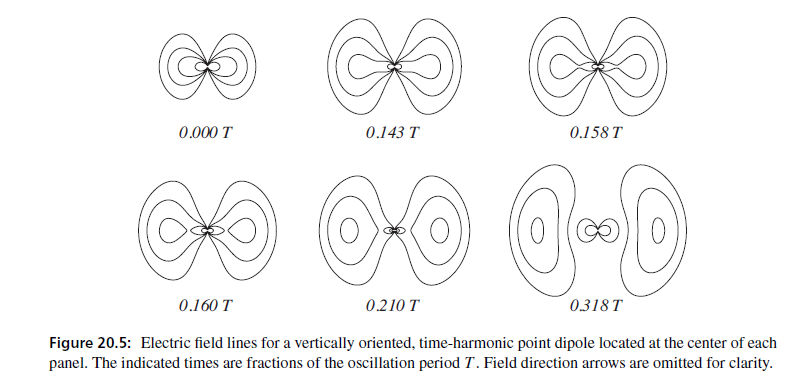)

## Referencias

1. Zangwill, A. (2013). Modern electrodynamics (Vol. 7). Cambridge: Cambridge University Press.

2. Griffiths, D. J. (2013). Introduction to electrodynamics. Cambridge University Press.

3. Jackson, J. D. (1999). Classical Electrodynamics (3.ª ed.). John Wiley & Sons.

https://github.com/Sherezax/TareaProgramadaElectro2_Evaluacion3/tree/main